# Data exploration and preparation


The project predicts, the day before, the chance that a scheduled bus departure at a stop
leaves more than 5 minutes late (BO-1) or more than 60 s early (BO-2). The MVP trains and evaluates a
model on one route in one direction, following CRISP-DM. This notebook covers the *data understanding*
and *data preparation* phases: it loads the main table and three side tables, explores them, cleans,
transforms and joins them, checks completeness, and saves one modelling table. Modelling comes in a
later notebook.

**Feature rule.** Every feature must be known the day before the departure. Same-day observed weather
is therefore **not** a model feature; the model uses the previous day's weather. Results with same-day
weather may be reported separately as an upper bound only.

All files are in `data/mvp/` and are re-created with:

```bash
uv run probe/export_mvp_slice.py     # main table
uv run probe/export_mvp_extras.py    # three side tables
```

### 0.1 Data sources

| File | Source | One row is | Rows | Period | Join key |
|---|---|---|---|---|---|
| `route91_st_norbert.csv` (main) | City of Winnipeg *Transit On-Time Performance*: archive [`cymk-nyei`](https://data.winnipeg.ca/d/cymk-nyei) + recent table [`gp3k-am4u`](https://data.winnipeg.ca/d/gp3k-am4u) | one departure of route 91 toward St. Norbert from one stop | 80,032 | 2025-07-04 to 2026-11-23 (gap 2026-10-01..09) | — |
| `weather_daily.csv` | [Open-Meteo](https://open-meteo.com/) historical archive API, point (49.78, −97.155) | one day | 511 | 2025-07-01 to 2026-11-23 | date |
| `calendar_daily.csv` | Manitoba statutory holidays; City of Winnipeg snow parking bans [`mfzv-893p`](https://data.winnipeg.ca/d/mfzv-893p) | one day | 511 | 2025-07-01 to 2026-11-23 | date |
| `stop_ridership.csv` | City of Winnipeg ridership by stop [`bv6q-du26`](https://data.winnipeg.ca/d/bv6q-du26) | one stop × time period × schedule period (weekday average) | 320 | 5 schedule periods, 2025-06-29 to 2026-09-05 | stop + time period + schedule period |

### 0.2 Fields

**Main table** `route91_st_norbert.csv`

| Field | Type | Meaning |
|---|---|---|
| `route_number` | string | Route, always `91` |
| `route_destination` | string | Headsign, always `St. Norbert` |
| `stop_number` | string | Stop ID (16 stops) |
| `day_type` | string | Service type; always `Weekday` here (a few rows fall on weekends or holidays) |
| `scheduled_time` | timestamp | Scheduled departure at the stop, local time, before 18:00 |
| `deviation` | int, seconds | Scheduled minus actual: **negative = late, positive = early** |
| `location` | WKT `POINT (lon lat)` | Stop coordinates |

**Weather** `weather_daily.csv` (observed, daily)

| Field | Type | Meaning |
|---|---|---|
| `date` | date | Calendar day |
| `temperature_2m_max`, `temperature_2m_min` | float, °C | Daily max / min air temperature |
| `precipitation_sum`, `rain_sum` | float, mm | Total precipitation; rain part |
| `snowfall_sum` | float, cm | Snowfall (may under-count, see the data-sources notes) |
| `wind_speed_10m_max` | float, km/h | Daily max wind speed at 10 m |
| `weather_code` | int (WMO code) | Dominant weather of the day |
| `weather_text` | string | Text label of `weather_code` (13 values) |

**Calendar** `calendar_daily.csv`

| Field | Type | Meaning |
|---|---|---|
| `date` | date | Calendar day |
| `is_holiday` | bool | Manitoba statutory holiday (Sunday service) |
| `day_before_holiday`, `day_after_holiday` | bool | Adjacent to a holiday |
| `snow_route_ban` | bool | Snow-route parking ban in force (2025-12-03 to 2026-04-02) |
| `residential_ban` | bool | Residential parking ban in force |

**Ridership** `stop_ridership.csv`

| Field | Type | Meaning |
|---|---|---|
| `schedule_period_name` | string | Schedule period, e.g. `Winter 2025` |
| `period_start`, `period_end` | date | Date range of the schedule period |
| `stop_number` | string | Stop ID |
| `time_period` | string | `Morning`, `Mid-Day`, `PM Peak`, `Evening` (boundaries not published) |
| `average_boardings`, `average_alightings` | float | Weekday average per trip at this stop and period |

### 0.3 Directory layout

This notebook is one part of a small set of files. Keep them in this layout when you copy or
download them, because the code finds the data and the helper modules by relative path:

```text
wpg-transit-reliability/
├── notebooks/
│   ├── 02-data-exploration-and-preparation.ipynb
│   ├── mvp_config.py
│   └── mvp_prep.py
│
├── data/mvp/
│   ├── route91_st_norbert.csv
│   ├── weather_daily.csv
│   ├── calendar_daily.csv
│   └── stop_ridership.csv
```

In [51]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# mvp_config.py and mvp_prep.py sit next to this notebook (see 0.3). Make them importable
# whether Jupyter starts in notebooks/ or in the repository root.
NB_DIR = Path.cwd() if (Path.cwd() / "mvp_config.py").exists() else Path.cwd() / "notebooks"
sys.path.insert(0, str(NB_DIR))

import mvp_config as cfg   # paths, thresholds, split date, time-period boundaries
import mvp_prep as prep    # one function per preparation step
from mvp_config import (DATA_PATH, WEATHER_PATH, CALENDAR_PATH, RIDERSHIP_PATH, PREPARED_PATH,
                        LATE_S, EARLY_S, MAX_ABS_DEV_S)

pd.set_option("display.max_columns", 80)

## 1. Load data

**Question.** Do the four files load with the expected rows, columns and types?

**Why.** Every later step depends on the tables loading cleanly. Stop numbers are read as strings in both tables that carry them, because they are identifiers and are used as a join key.

In [53]:
df = pd.read_csv(DATA_PATH, dtype={"route_number": str, "stop_number": str})
weather = pd.read_csv(WEATHER_PATH, parse_dates=["date"])
calendar = pd.read_csv(CALENDAR_PATH, parse_dates=["date"])
ridership = pd.read_csv(RIDERSHIP_PATH, dtype={"stop_number": str},
                        parse_dates=["period_start", "period_end"])

tables = {"main": df, "weather": weather, "calendar": calendar, "ridership": ridership}
pd.DataFrame({name: t.shape for name, t in tables.items()}, index=["rows", "columns"]).T

,rows,columns
main,80032,7
weather,511,9
calendar,511,6
ridership,320,7


Structure of each table: column types, non-null counts and memory. Descriptive statistics (`describe`) come in section 2.1.

In [54]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80032 entries, 0 to 80031
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   route_number       80032 non-null  object
 1   route_destination  80032 non-null  object
 2   stop_number        80032 non-null  object
 3   day_type           80032 non-null  object
 4   scheduled_time     80032 non-null  object
 5   deviation          80032 non-null  int64 
 6   location           80032 non-null  object
dtypes: int64(1), object(6)
memory usage: 4.3+ MB


In [55]:
df.head()

,route_number,route_destination,stop_number,day_type,scheduled_time,deviation,location
0,91,St. Norbert,60061,Weekday,2025-07-04 05:26:00,571,POINT (-97.1543789828127 49.7898958919121)
1,91,St. Norbert,60064,Weekday,2025-07-04 05:27:00,-60,POINT (-97.1565841949361 49.7896341634893)
2,91,St. Norbert,60033,Weekday,2025-07-04 05:27:58,-46,POINT (-97.1573715725763 49.7860936041922)
3,91,St. Norbert,60028,Weekday,2025-07-04 05:29:13,-6,POINT (-97.1570813253442 49.7812945667731)
4,91,St. Norbert,60026,Weekday,2025-07-04 05:29:42,8,POINT (-97.1569697482449 49.7794757683298)


In [56]:
weather.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 511 entries, 0 to 510
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   date                511 non-null    datetime64[ns]
 1   temperature_2m_max  511 non-null    float64       
 2   temperature_2m_min  511 non-null    float64       
 3   precipitation_sum   511 non-null    float64       
 4   rain_sum            511 non-null    float64       
 5   snowfall_sum        511 non-null    float64       
 6   wind_speed_10m_max  511 non-null    float64       
 7   weather_code        511 non-null    int64         
 8   weather_text        511 non-null    object        
dtypes: datetime64[ns](1), float64(6), int64(1), object(1)
memory usage: 36.1+ KB


In [57]:
weather.head()

,date,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,snowfall_sum,wind_speed_10m_max,weather_code,weather_text
0,2025-07-01,28.7,18.1,0.0,0.0,0.0,19.4,3,overcast
1,2025-07-02,29.6,17.9,0.0,0.0,0.0,13.1,3,overcast
2,2025-07-03,32.5,16.7,0.0,0.0,0.0,19.9,3,overcast
3,2025-07-04,29.7,20.4,17.9,17.9,0.0,19.8,65,heavy rain
4,2025-07-05,23.6,15.8,0.0,0.0,0.0,16.6,3,overcast


In [58]:
calendar.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 511 entries, 0 to 510
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   date                511 non-null    datetime64[ns]
 1   is_holiday          511 non-null    bool          
 2   day_before_holiday  511 non-null    bool          
 3   day_after_holiday   511 non-null    bool          
 4   snow_route_ban      511 non-null    bool          
 5   residential_ban     511 non-null    bool          
dtypes: bool(5), datetime64[ns](1)
memory usage: 6.6 KB


In [59]:
calendar.head()

,date,is_holiday,day_before_holiday,day_after_holiday,snow_route_ban,residential_ban
0,2025-07-01,True,False,False,False,False
1,2025-07-02,False,False,True,False,False
2,2025-07-03,False,False,False,False,False
3,2025-07-04,False,False,False,False,False
4,2025-07-05,False,False,False,False,False


In [60]:
ridership.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 320 entries, 0 to 319
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   schedule_period_name  320 non-null    object        
 1   period_start          320 non-null    datetime64[ns]
 2   period_end            320 non-null    datetime64[ns]
 3   stop_number           320 non-null    object        
 4   time_period           320 non-null    object        
 5   average_boardings     320 non-null    float64       
 6   average_alightings    320 non-null    float64       
dtypes: datetime64[ns](2), float64(2), object(3)
memory usage: 17.6+ KB


In [61]:
ridership.head()

,schedule_period_name,period_start,period_end,stop_number,time_period,average_boardings,average_alightings
0,Summer 2025,2025-06-29,2025-08-30,60016,Evening,0.0,0.3
1,Summer 2025,2025-06-29,2025-08-30,60016,Mid-Day,0.5,1.0
2,Summer 2025,2025-06-29,2025-08-30,60016,Morning,0.1,0.7
3,Summer 2025,2025-06-29,2025-08-30,60016,PM Peak,0.1,1.0
4,Summer 2025,2025-06-29,2025-08-30,60017,Evening,0.4,0.9


In [62]:
# Distinct values per column: shows constant columns and identifier cardinality at a glance.
pd.concat({name: t.nunique() for name, t in tables.items()}).rename("n_distinct").to_frame()

n_distinct
main      route_number                   1
          route_destination              1
          stop_number                   16
          day_type                       1
          scheduled_time             80014
          deviation                   1313
          location                      16
weather   date                         511
          temperature_2m_max           307
          temperature_2m_min           290
          precipitation_sum             92
          rain_sum                      84
          snowfall_sum                  36
          wind_speed_10m_max           210
          weather_code                  13
          weather_text                  13
calendar  date                         511
          is_holiday                     2
          day_before_holiday             2
          day_after_holiday              2
          snow_route_ban                 2
          residential_ban                2
ridership schedule_period_name           5
          period_start                   5
          period_end                     5
          stop_number                   16
          time_period                    4
          average_boardings             63
          average_alightings            63

In [63]:
# Schema check: the columns each later step relies on.
expected = {
    "main": ["route_number", "route_destination", "stop_number", "day_type",
             "scheduled_time", "deviation", "location"],
    "weather": ["date", "temperature_2m_max", "temperature_2m_min", "precipitation_sum", "rain_sum",
                "snowfall_sum", "wind_speed_10m_max", "weather_code", "weather_text"],
    "calendar": ["date", "is_holiday", "day_before_holiday", "day_after_holiday",
                 "snow_route_ban", "residential_ban"],
    "ridership": ["schedule_period_name", "period_start", "period_end", "stop_number",
                  "time_period", "average_boardings", "average_alightings"],
}
for name, cols in expected.items():
    assert list(tables[name].columns) == cols, (name, list(tables[name].columns))
print("schemas OK")

schemas OK


In [64]:
# Time span of each table: the side tables must cover every date of the main table.
main_ts = pd.to_datetime(df["scheduled_time"])
pd.DataFrame({
    "first": [main_ts.min(), weather["date"].min(), calendar["date"].min(), ridership["period_start"].min()],
    "last": [main_ts.max(), weather["date"].max(), calendar["date"].max(), ridership["period_end"].max()],
}, index=["main (scheduled_time)", "weather (date)", "calendar (date)", "ridership (period)"])

,first,last
main (scheduled_time),2025-07-04 05:26:00,2026-11-23 17:58:14
weather (date),2025-07-01 00:00:00,2026-11-23 00:00:00
calendar (date),2025-07-01 00:00:00,2026-11-23 00:00:00
ridership (period),2025-06-29 00:00:00,2026-09-05 00:00:00


In [65]:
# Missing values per table after loading (0 everywhere means no cell is empty).
pd.DataFrame({name: [int(t.isna().sum().sum()), int(t.isna().any(axis=1).sum())]
              for name, t in tables.items()},
             index=["empty cells", "rows with any empty cell"]).T

,empty cells,rows with any empty cell
main,0,0
weather,0,0
calendar,0,0
ridership,0,0


### Findings (1)

- **All four files load with the expected shape and columns** (schema check passes):
  main 80,032 × 7, weather 511 × 9, calendar 511 × 6, ridership 320 × 7.
- **No empty cells** in any table, so missing data in this project means *missing rows*
  (whole days absent from the main table), not missing values. Section 6 deals with it.
- **Main table**: 16 stops, each with one location. `route_number`, `route_destination` and `day_type`
  each hold a single value (`91`, `St. Norbert`, `Weekday`), so they carry no information for the model.
  `deviation` has 1,313 distinct values. `scheduled_time` has 80,014 distinct values for 80,032 rows;
  the repeats are checked as possible duplicates in section 3.2.
- **Time span**: the main table runs from 2025-07-04 05:26 to 2026-11-23 17:58. Weather and calendar
  cover 2025-07-01 to 2026-11-23, one row per day, so they span every main-table date.
  Ridership has 5 schedule periods (2025-06-29 to 2026-09-05), 16 stops and 4 time periods;
  it does **not** cover service dates after 2026-09-05 (handled in section 6.3).
- **Types**: `scheduled_time` is still text; it is parsed in section 3.1. Stop numbers are strings in both
  tables that carry them, so they can be used as a join key.

## 2. Exploratory data analysis

**Question.** How is `deviation` distributed, how are records spread over hours, stops, months and weekdays, and what do the side tables contain?

**Why.** The targets are thresholds on `deviation`, so its shape decides how rare the positive classes are. The spread over time and stops shows where data is thin; the side tables show whether their features vary enough over the MVP period to be useful.

### 2.1 Descriptive statistics

In [66]:
# Main table: deviation in seconds (negative = late, positive = early), with tail percentiles.
df["deviation"].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).round(1)

count    80032.0
mean       -64.7
std        145.3
min      -2968.0
1%        -489.0
5%        -300.4
25%       -138.0
50%        -45.0
75%         25.0
95%        110.0
99%        186.0
max       2146.0
Name: deviation, dtype: float64

In [67]:
# Main table: text columns (count, distinct values, most frequent value and its count).
df.select_dtypes(exclude="number").describe().T

,count,unique,top,freq
route_number,80032,1,91,80032
route_destination,80032,1,St. Norbert,80032
stop_number,80032,16,60064,5180
day_type,80032,1,Weekday,80032
scheduled_time,80032,80014,2026-01-30 09:08:39,2
location,80032,16,POINT (-97.1565841949361 49.7896341634893),5180


In [68]:
# Share of rows past each target threshold, before any cleaning.
pd.Series({
    f"late > {LATE_S} s (deviation < -{LATE_S})": (df["deviation"] < -LATE_S).mean(),
    f"early > {EARLY_S} s (deviation > {EARLY_S})": (df["deviation"] > EARLY_S).mean(),
    f"|deviation| > {MAX_ABS_DEV_S} s": (df["deviation"].abs() > MAX_ABS_DEV_S).mean(),
}).map("{:.2%}".format).to_frame("share of rows")

,share of rows
late > 300 s (deviation < -300),5.00%
early > 60 s (deviation > 60),13.98%
|deviation| > 3600 s,0.00%


In [69]:
# Weather: numeric measurements only. weather_code is a category; its counts are in section 2.3.
weather.drop(columns=["date", "weather_code"]).describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
temperature_2m_max,511.0,11.7,13.9,-27.2,1.8,15.3,23.3,36.1
temperature_2m_min,511.0,2.3,13.6,-36.2,-6.4,5.1,13.8,25.4
precipitation_sum,511.0,1.9,4.4,0.0,0.0,0.1,1.7,43.0
rain_sum,511.0,1.6,4.3,0.0,0.0,0.0,0.8,43.0
snowfall_sum,511.0,0.2,0.7,0.0,0.0,0.0,0.0,6.4
wind_speed_10m_max,511.0,18.6,6.3,5.3,13.9,18.0,22.0,44.1


In [70]:
# Calendar flags: number and share of days each flag is set.
flags = calendar.drop(columns="date")
pd.DataFrame({"days": flags.sum(), "share": flags.mean().map("{:.1%}".format)})

,days,share
is_holiday,18,3.5%
day_before_holiday,17,3.3%
day_after_holiday,18,3.5%
snow_route_ban,121,23.7%
residential_ban,6,1.2%


In [71]:
ridership[["average_boardings", "average_alightings"]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
average_boardings,320.0,1.66,3.17,0.0,0.1,0.5,1.9,28.1
average_alightings,320.0,1.56,2.12,0.0,0.3,0.7,2.1,14.2


In [72]:
# Ridership by time period, averaged over stops and schedule periods.
ridership.groupby("time_period")[["average_boardings", "average_alightings"]].mean().round(2)

,average_boardings,average_alightings
time_period,,
Evening,0.63,0.60
Mid-Day,2.86,2.46
Morning,1.22,1.11
PM Peak,1.93,2.06


### 2.2 Distributions: main table

In [73]:
# Plot style for this notebook: one hue per series, recessive grid, no top/right spines.
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8984"   # series 1, series 2, reference lines
plt.rcParams.update({
    "figure.figsize": (9, 3.6), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8, "legend.frameon": False,
})

# scheduled_time is parsed for good in section 3.1; here a parsed copy is enough for plotting.
ts = pd.to_datetime(df["scheduled_time"])
service_date = ts.dt.normalize()
WEEKDAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

# Stops in route order. There is no stop sequence in the data; route 91 runs south toward
# St. Norbert, so stops are ordered north -> south by latitude (an approximation).
stop_lat = df.groupby("stop_number")["location"].first().str.extract(r"POINT \(\S+ (\S+)\)")[0].astype(float)
STOP_ORDER = stop_lat.sort_values(ascending=False).index.tolist()

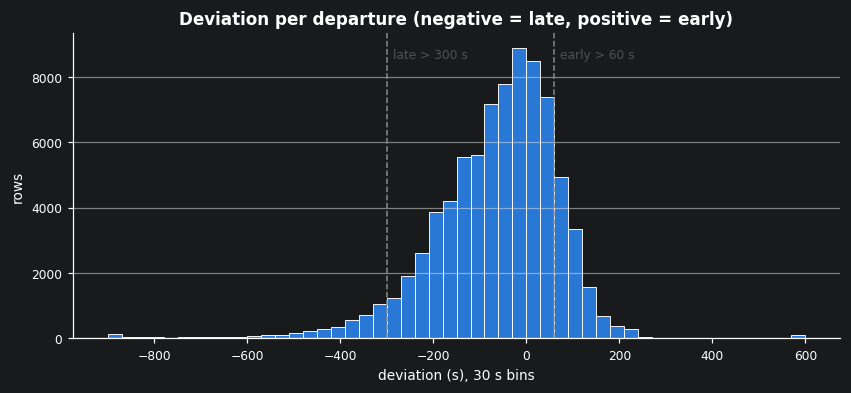

clipped below -900 s: 112 rows; above 600 s: 89 rows


In [74]:
# Deviation: clipped to [-900, +600] s for readability (the clipped tails are counted below).
lo, hi = -900, 600
fig, ax = plt.subplots()
ax.hist(df["deviation"].clip(lo, hi), bins=range(lo, hi + 30, 30), color=BLUE, edgecolor="white", linewidth=0.6)
for x, label in [(-LATE_S, f"late > {LATE_S} s"), (EARLY_S, f"early > {EARLY_S} s")]:
    ax.axvline(x, color=GREY, linestyle="--", linewidth=1)
    ax.annotate(label, (x, ax.get_ylim()[1] * 0.92), xytext=(4, 0), textcoords="offset points", fontsize=8, color="#52514e")
ax.set(title="Deviation per departure (negative = late, positive = early)", xlabel="deviation (s), 30 s bins", ylabel="rows")
plt.show()
print(f"clipped below {lo} s: {(df['deviation'] < lo).sum():,} rows; above {hi} s: {(df['deviation'] > hi).sum():,} rows")

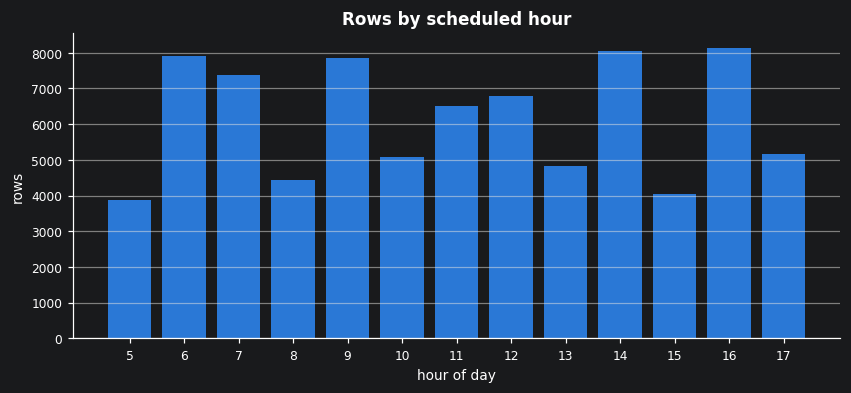

In [75]:
# Rows by scheduled hour (the slice stops at 18:00).
by_hour = ts.dt.hour.value_counts().sort_index()
fig, ax = plt.subplots()
ax.bar(by_hour.index, by_hour.values, color=BLUE, width=0.8)
ax.set(title="Rows by scheduled hour", xlabel="hour of day", ylabel="rows", xticks=by_hour.index)
plt.show()

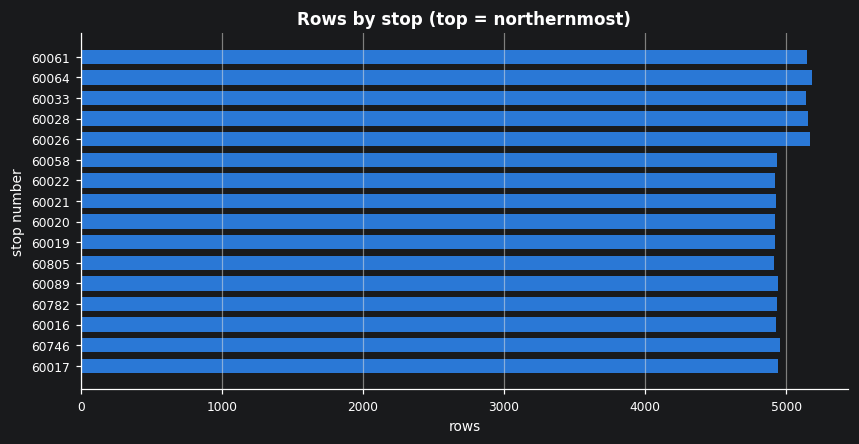

In [76]:
# Rows by stop, in approximate route order (north -> south).
by_stop = df["stop_number"].value_counts().reindex(STOP_ORDER)
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(by_stop.index[::-1], by_stop.values[::-1], color=BLUE, height=0.7)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set(title="Rows by stop (top = northernmost)", xlabel="rows", ylabel="stop number")
plt.show()

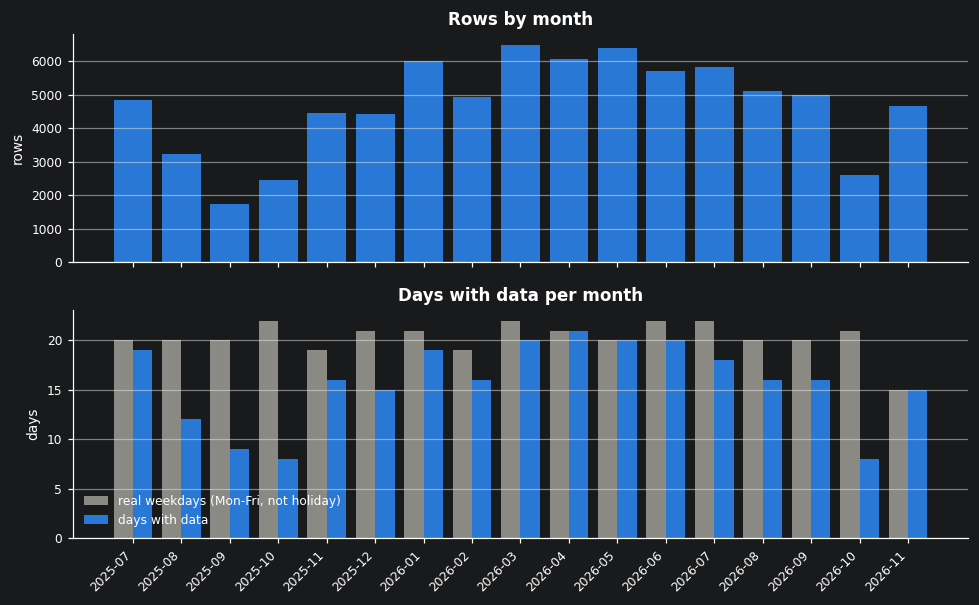

date,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10,2026-11
real weekdays,20,20,20,22,19,21,21,19,22,21,20,22,22,20,20,21,15
weekdays with data,19,12,9,8,16,15,19,16,20,21,20,20,18,16,16,8,15


In [77]:
# Rows by month, and observed vs real weekdays by month (two panels, one y-scale each).
real_weekdays = calendar.loc[(calendar["date"].dt.day_of_week < 5) & ~calendar["is_holiday"]
                             & (calendar["date"] >= service_date.min()), "date"]
month = lambda s: s.dt.to_period("M")
rows_by_month = ts.dt.to_period("M").value_counts().sort_index()
days = pd.DataFrame({
    "real weekdays": month(real_weekdays).value_counts(),
    "weekdays with data": month(real_weekdays[real_weekdays.isin(service_date.unique())]).value_counts(),
}).fillna(0).astype(int).sort_index()
days = days.loc[days.index >= rows_by_month.index.min()]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 5.6), sharex=True)
x = np.arange(len(days))
ax1.bar(x, rows_by_month.reindex(days.index, fill_value=0).values, color=BLUE, width=0.8)
ax1.set(title="Rows by month", ylabel="rows")
ax2.bar(x - 0.2, days["real weekdays"], width=0.4, color=GREY, label="real weekdays (Mon-Fri, not holiday)")
ax2.bar(x + 0.2, days["weekdays with data"], width=0.4, color=BLUE, label="days with data")
ax2.set(title="Days with data per month", ylabel="days")
ax2.set_xticks(x, [str(p) for p in days.index], rotation=45, ha="right")
ax2.legend(loc="lower left")
plt.tight_layout(); plt.show()
days.T

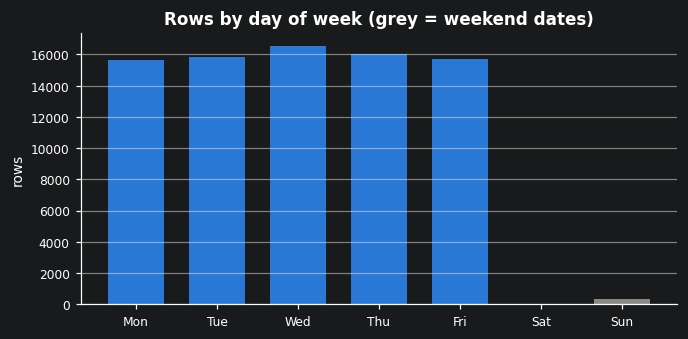

,Mon,Tue,Wed,Thu,Fri,Sat,Sun
rows,15628,15822,16525,16010,15722,0,325


In [78]:
# Rows by weekday. Saturday/Sunday rows are Weekday-labelled records on weekend dates (removed in 3.4).
by_wd = ts.dt.day_of_week.value_counts().reindex(range(7), fill_value=0)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar([WEEKDAYS[i] for i in by_wd.index], by_wd.values, color=[BLUE] * 5 + [GREY] * 2, width=0.7)
ax.set(title="Rows by day of week (grey = weekend dates)", ylabel="rows")
plt.show()
by_wd.set_axis(WEEKDAYS).to_frame("rows").T

### 2.3 Distributions: side tables

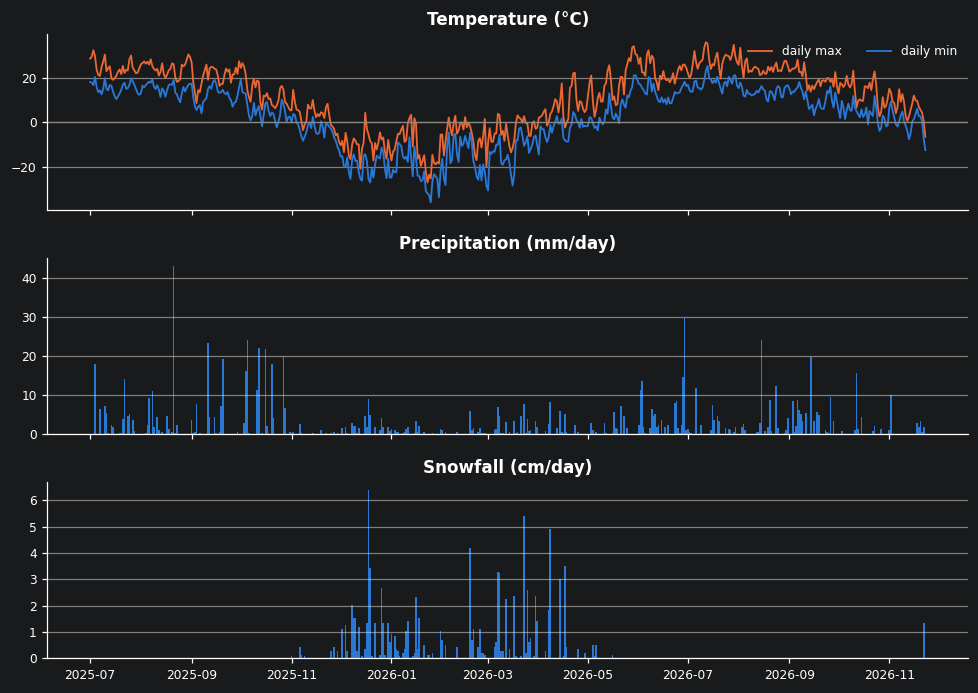

In [79]:
# Weather over the MVP period: three panels, one unit each.
fig, axes = plt.subplots(3, 1, figsize=(9, 6.4), sharex=True)
axes[0].plot(weather["date"], weather["temperature_2m_max"], color=ORANGE, linewidth=1.2, label="daily max")
axes[0].plot(weather["date"], weather["temperature_2m_min"], color=BLUE, linewidth=1.2, label="daily min")
axes[0].axhline(0, color=GREY, linewidth=0.8)
axes[0].set(title="Temperature (°C)"); axes[0].legend(loc="upper right", ncols=2)
axes[1].bar(weather["date"], weather["precipitation_sum"], color=BLUE, width=1.0)
axes[1].set(title="Precipitation (mm/day)")
axes[2].bar(weather["date"], weather["snowfall_sum"], color=BLUE, width=1.0)
axes[2].set(title="Snowfall (cm/day)")
plt.tight_layout(); plt.show()

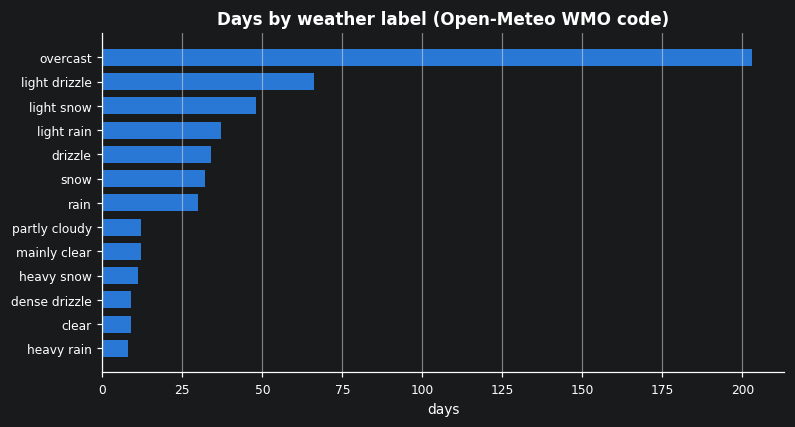

weather_text,overcast,light drizzle,light snow,light rain,drizzle,snow,rain,mainly clear,partly cloudy,heavy snow,clear,dense drizzle,heavy rain
all days,203,66,48,37,34,32,30,12,12,11,9,9,8
days with data,101,33,26,25,16,23,17,4,6,5,4,5,5


In [80]:
# Weather labels: all days vs days that have main-table records.
obs_days = set(service_date.unique())
wx_counts = pd.DataFrame({
    "all days": weather["weather_text"].value_counts(),
    "days with data": weather.loc[weather["date"].isin(obs_days), "weather_text"].value_counts(),
}).fillna(0).astype(int).sort_values("all days")
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(wx_counts.index, wx_counts["all days"], color=BLUE, height=0.7)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set(title="Days by weather label (Open-Meteo WMO code)", xlabel="days")
plt.show()
wx_counts.sort_values("all days", ascending=False).T

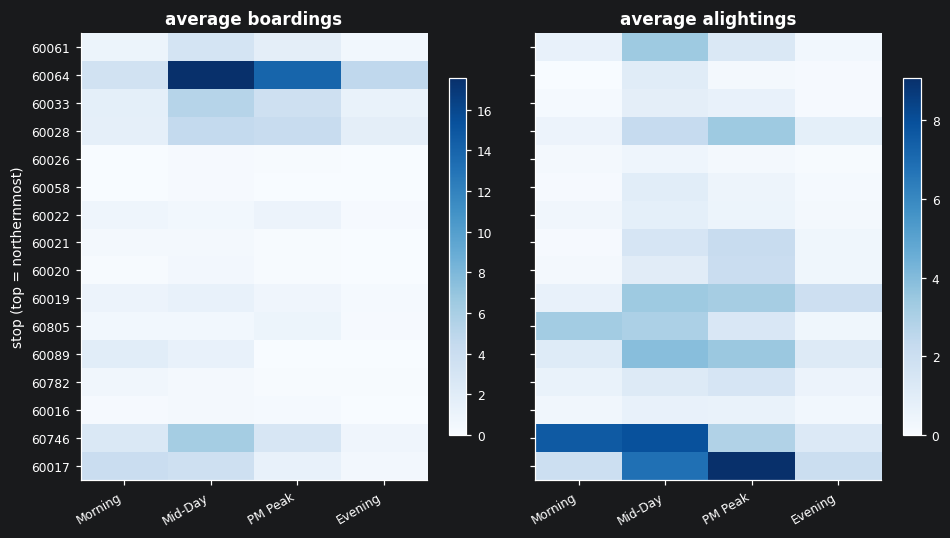

,,average_boardings,average_alightings
period_start,schedule_period_name,,
2025-06-29,Summer 2025,87.6,82.8
2025-08-31,Summer 2025 Special,139.0,130.3
2025-12-14,Winter 2025,115.8,110.1
2026-04-12,Spring 2026,107.9,99.1
2026-06-21,Summer 2026,80.5,75.6


In [81]:
# Ridership: average boardings per trip by stop and time period (mean over the 5 schedule periods).
PERIOD_ORDER = ["Morning", "Mid-Day", "PM Peak", "Evening"]
fig, axes = plt.subplots(1, 2, figsize=(9, 5), sharey=True)
for ax, col in zip(axes, ["average_boardings", "average_alightings"]):
    grid = ridership.pivot_table(index="stop_number", columns="time_period", values=col, aggfunc="mean")
    grid = grid.reindex(index=STOP_ORDER, columns=PERIOD_ORDER)
    im = ax.imshow(grid.values, cmap="Blues", aspect="auto", vmin=0)
    ax.set_xticks(range(len(PERIOD_ORDER)), PERIOD_ORDER, rotation=30, ha="right")
    ax.set_yticks(range(len(grid)), grid.index); ax.grid(False)
    ax.set_title(col.replace("_", " "))
    fig.colorbar(im, ax=ax, shrink=0.8)
axes[0].set_ylabel("stop (top = northernmost)")
plt.tight_layout(); plt.show()

# Stability across schedule periods: route-level totals per period.
ridership.groupby(["period_start", "schedule_period_name"])[["average_boardings", "average_alightings"]].sum().round(1)

### 2.4 First look at relationships

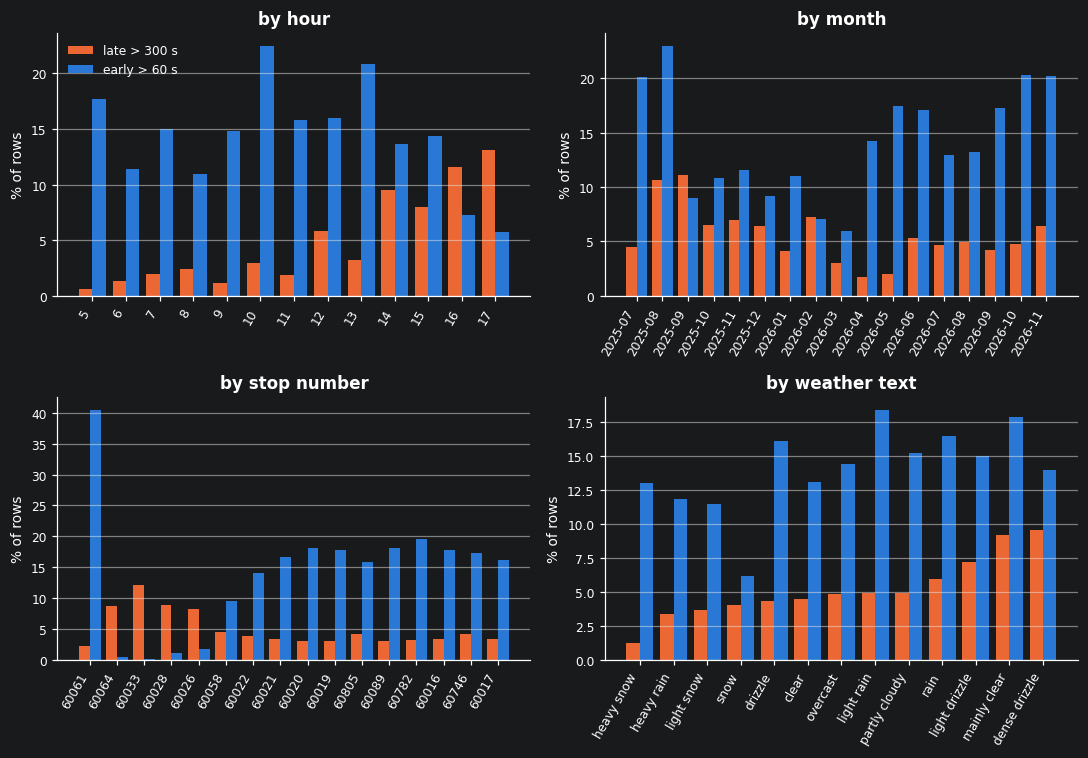

late  early
               snow_route_ban             
snow_route_ban False           5.06  16.24
               True            4.85   7.97
snowfall > 0   False           5.37  15.19
               True            3.57   9.33

In [82]:
# Late / early rates by group. Same-day weather and calendar are joined here for description only;
# features in section 4 use previous-day weather.
look = pd.DataFrame({"hour": ts.dt.hour, "stop_number": df["stop_number"], "month": ts.dt.to_period("M").astype(str),
                     "date": service_date, "late": df["deviation"] < -LATE_S, "early": df["deviation"] > EARLY_S})
look = (look.merge(weather[["date", "weather_text", "snowfall_sum"]], on="date", how="left")
            .merge(calendar[["date", "snow_route_ban"]], on="date", how="left"))
rate = lambda key: look.groupby(key)[["late", "early"]].mean().mul(100)

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, key, order in [(axes[0, 0], "hour", None), (axes[0, 1], "month", None),
                       (axes[1, 0], "stop_number", STOP_ORDER), (axes[1, 1], "weather_text", None)]:
    r = rate(key)
    r = r.reindex(order) if order else (r.sort_values("late") if key == "weather_text" else r)
    x = np.arange(len(r))
    ax.bar(x - 0.2, r["late"], width=0.4, color=ORANGE, label=f"late > {LATE_S} s")
    ax.bar(x + 0.2, r["early"], width=0.4, color=BLUE, label=f"early > {EARLY_S} s")
    ax.set_xticks(x, r.index, rotation=60 if len(r) > 8 else 0, ha="right" if len(r) > 8 else "center")
    ax.set(title=f"by {key.replace('_', ' ')}", ylabel="% of rows")
axes[0, 0].legend(loc="upper left")
plt.tight_layout(); plt.show()

pd.concat({"snow_route_ban": rate("snow_route_ban"),
           "snowfall > 0": rate(look["snowfall_sum"] > 0)}).round(2)

### 2.5 Value ranges per feature

In [83]:
# Value range of every column: type, min, max, distinct values and empty cells.
def value_ranges(t):
    return pd.DataFrame({
        "dtype": t.dtypes.astype(str),
        "min": t.min(numeric_only=False),
        "max": t.max(numeric_only=False),
        "n_distinct": t.nunique(),
        "n_null": t.isna().sum(),
    })

pd.concat({name: value_ranges(t) for name, t in tables.items()})

dtype  \
main      route_number                  object   
          route_destination             object   
          stop_number                   object   
          day_type                      object   
          scheduled_time                object   
          deviation                      int64   
          location                      object   
weather   date                  datetime64[ns]   
          temperature_2m_max           float64   
          temperature_2m_min           float64   
          precipitation_sum            float64   
          rain_sum                     float64   
          snowfall_sum                 float64   
          wind_speed_10m_max           float64   
          weather_code                   int64   
          weather_text                  object   
calendar  date                  datetime64[ns]   
          is_holiday                      bool   
          day_before_holiday              bool   
          day_after_holiday               bool   
          snow_route_ban                  bool   
          residential_ban                 bool   
ridership schedule_period_name          object   
          period_start          datetime64[ns]   
          period_end            datetime64[ns]   
          stop_number                   object   
          time_period                   object   
          average_boardings            float64   
          average_alightings           float64   

                                                                       min  \
main      route_number                                                  91   
          route_destination                                    St. Norbert   
          stop_number                                                60016   
          day_type                                                 Weekday   
          scheduled_time                               2025-07-04 05:26:00   
          deviation                                                  -2968   
          location              POINT (-97.1543789828127 49.7898958919121)   
weather   date                                         2025-07-01 00:00:00   
          temperature_2m_max                                         -27.2   
          temperature_2m_min                                         -36.2   
          precipitation_sum                                            0.0   
          rain_sum                                                     0.0   
          snowfall_sum                                                 0.0   
          wind_speed_10m_max                                           5.3   
          weather_code                                                   0   
          weather_text                                               clear   
calendar  date                                         2025-07-01 00:00:00   
          is_holiday                                                 False   
          day_before_holiday                                         False   
          day_after_holiday                                          False   
          snow_route_ban                                             False   
          residential_ban                                            False   
ridership schedule_period_name                                 Spring 2026   
          period_start                                 2025-06-29 00:00:00   
          period_end                                   2025-08-30 00:00:00   
          stop_number                                                60016   
          time_period                                              Evening   
          average_boardings                                            0.0   
          average_alightings                                           0.0   

                                                                       max  \
main      route_number                                                  91   
          route_destination                

### Findings (2)

**Deviation and targets**
- The distribution is centred slightly late: median −45 s, mean −65 s, middle half from −138 s to +25 s.
  The tails are long on both sides (most late −2,968 s, most early +2,146 s); 112 rows are below −900 s and 89 above +600 s.
- Base rates before cleaning: **5.0 % late > 300 s** (BO-1) and **14.0 % early > 60 s** (BO-2).
  Both classes are minorities, BO-1 strongly so, so evaluation needs probability scores (e.g. Brier) rather than accuracy.
- No row has |deviation| > 3,600 s.

**Coverage over hours, stops, months and weekdays**
- Rows cover 05:00–17:59 at every stop; each of the 16 stops has 4,900–5,200 rows, so no stop is thin.
- Rows are spread evenly over Monday–Friday (15,600–16,500 each). **325 rows fall on Sundays** although labelled `Weekday`;
  they and the holiday rows are removed in 3.4.
- Coverage is uneven over time. Only **268 of the 338 real weekdays** have data (2025-07-04 to 2026-11-23, without the
  2026-10-01..09 gap between archive and recent table). The worst months are 2025-08 to 2025-10
  (12, 9 and 8 days of 20–22) and 2026-10 (8 of 21). Section 6 treats this.

**First look at relationships** (descriptive, not yet a model)
- **Hour** matters most: late > 300 s is 1–3 % before 10:00 and rises to 10–13 % from 14:00 to 17:59.
  Early > 60 s is highest late morning and early afternoon (21–22 % at 10:00 and 13:00).
- **Stop** matters as much: the first stop, 60061, is early in 40 % of rows (buses leave the start of the route early);
  the next four stops are late 8–12 % and almost never early; the remaining stops are late 3–4 % and early 15–20 %.
  Stop order here is approximated by latitude, because the data has no stop sequence.
- **Month**: late is highest in 2025-08 and 2025-09 (about 11 %) and lowest in 2026-03 to 2026-05 (2–3 %);
  early swings from 6 % to 23 %. Part of this may be the uneven coverage of those months.
- **Same-day weather and calendar** show no simple pattern. Snow days are *less* often late (3.6 % vs 5.4 %), and
  snow-route-ban days are much less often early (8 % vs 16 %). Both overlap with winter months, so season and weather
  are confounded here. Weather labels with few days (heavy rain 8 days, dense drizzle 9) give unstable rates.

**Side tables**
- Weather varies widely over the period (−36 °C to +36 °C; precipitation up to 43 mm/day; snowfall up to 6.4 cm/day,
  with snow on 91 of 511 days). Snowfall is probably under-counted by the source.
- Calendar flags: snow-route ban 121 days (24 %), holidays 18, days before / after a holiday 17 / 18,
  residential ban only **6 days**, too rare to learn from on its own.
- Ridership is concentrated at a few stops: boardings at 60064 (about 17 per trip at mid-day) and alightings at 60746
  and 60017 near the end of the route. Route totals change between schedule periods (80 to 139 boardings per trip),
  so the period must be part of the join key.

**Kept for preparation**: hour, stop, month / season, previous-day weather, calendar flags except possibly
`residential_ban`, and ridership by stop × time period × schedule period.

## 3. Pre-processing

**Question.** Which rows or values must be fixed or removed before features are built?

**Why.** Wrong types, duplicates, impossible deviations or non-weekday rows would bias both the targets and the lag features. Each task states its reason.

### 3.1 Parse timestamps

*Reason:* `scheduled_time` arrives as text; date parts, the service date and the joins need a real timestamp.

In [84]:
# prep.parse_times parses with a fixed format (a bad value raises) and adds service_date.
df = prep.parse_times(df)
assert df["scheduled_time"].notna().all()

# Row count after each pre-processing step, shown at the end of section 3.
prep_log = [("loaded", len(df))]
df["scheduled_time"].dtype, df["scheduled_time"].min(), df["scheduled_time"].max()

(dtype('<M8[ns]'),
 Timestamp('2025-07-04 05:26:00'),
 Timestamp('2026-11-23 17:58:14'))

### 3.2 Duplicate check

*Reason:* a departure counted twice weighs twice in training. The route-quality check found about 0.03% duplicates on this route.

All duplicated keys turn out to have conflicting deviations, so all copies of a duplicated key are dropped rather than keeping one at random.

In [85]:
KEY = ["stop_number", "scheduled_time"]   # one scheduled departure at one stop
exact = df.duplicated().sum()
on_key = df.duplicated(KEY, keep=False)
dups = df[on_key].sort_values(KEY)
conflicting = dups.groupby(KEY)["deviation"].nunique().gt(1).sum()
print(f"exact duplicate rows: {exact}")
print(f"rows sharing a (stop, scheduled time) key: {on_key.sum()} "
      f"in {dups.groupby(KEY).ngroups} keys; keys whose copies disagree on deviation: {conflicting}")
dups.head(10)

exact duplicate rows: 0
rows sharing a (stop, scheduled time) key: 36 in 18 keys; keys whose copies disagree on deviation: 18


,route_number,route_destination,stop_number,day_type,scheduled_time,deviation,location,service_date
6741,91,St. Norbert,60016,Weekday,2025-08-19 16:11:25,1267,POINT (-97.1604046807776 49.7672699488352),2025-08-19
6742,91,St. Norbert,60016,Weekday,2025-08-19 16:11:25,-795,POINT (-97.1604046807776 49.7672699488352),2025-08-19
15538,91,St. Norbert,60026,Weekday,2025-11-21 11:37:14,-670,POINT (-97.1569697482449 49.7794757683298),2025-11-21
15539,91,St. Norbert,60026,Weekday,2025-11-21 11:37:14,-215,POINT (-97.1569697482449 49.7794757683298),2025-11-21
26958,91,St. Norbert,60026,Weekday,2026-01-30 09:06:58,-582,POINT (-97.1569697482449 49.7794757683298),2026-01-30
26959,91,St. Norbert,60026,Weekday,2026-01-30 09:06:58,-98,POINT (-97.1569697482449 49.7794757683298),2026-01-30
41542,91,St. Norbert,60026,Weekday,2026-04-15 17:58:14,-149,POINT (-97.1569697482449 49.7794757683298),2026-04-15
41543,91,St. Norbert,60026,Weekday,2026-04-15 17:58:14,2146,POINT (-97.1569697482449 49.7794757683298),2026-04-15
15536,91,St. Norbert,60028,Weekday,2025-11-21 11:36:40,-691,POINT (-97.1570813253442 49.7812945667731),2025-11-21
15537,91,St. Norbert,60028,Weekday,2025-11-21 11:36:40,-234,POINT (-97.1570813253442 49.7812945667731),2025-11-21


In [86]:
# Every duplicated key has copies with different deviations, so there is no way to tell which copy
# is the real departure. Keeping "the first" would be an arbitrary pick (and some copies are extreme,
# e.g. +2,146 s). All copies of such keys are dropped: 0.05 % of rows.
df = prep.drop_conflicting_duplicates(df)
assert not df.duplicated(KEY).any()
prep_log.append(("drop duplicated (stop, scheduled time)", len(df)))
len(df)

79996

### 3.3 Drop |deviation| > 3600 s

*Reason:* deviations beyond one hour are recording errors, not service. The rule is kept for reuse on other routes; this slice has **zero** such rows.

In [87]:
print(f"rows with |deviation| > {MAX_ABS_DEV_S} s: {(df['deviation'].abs() > MAX_ABS_DEV_S).sum()}")   # 0 here
df = prep.drop_extreme_deviation(df)
prep_log.append((f"drop |deviation| > {MAX_ABS_DEV_S} s", len(df)))

rows with |deviation| > 3600 s: 0


### 3.4 Keep real weekdays only

*Reason:* statutory holidays run Sunday service, and a few `Weekday` rows fall on weekends or holidays. The export kept them: 325 rows on Saturday/Sunday and 95 on holidays, 420 in total. They are removed using the calendar table.

In [88]:
assert (df["day_type"] == "Weekday").all()

# Which dates are affected, and how many rows each (diagnostic only).
weekdays = prep.real_weekdays(calendar)
odd = df.loc[~df["service_date"].isin(weekdays), "service_date"]
print(f"rows not on a real weekday: {len(odd)}")
print(odd.dt.strftime("%Y-%m-%d %a").value_counts().to_string())

df = prep.keep_real_weekdays(df, calendar)
prep_log.append(("keep real weekdays (Mon-Fri, not holiday)", len(df)))

rows not on a real weekday: 420
service_date
2025-10-19 Sun    325
2025-09-01 Mon     95


### 3.5 Side-table checks

*Reason:* a join can only be trusted if each side table has exactly one row per key and no nulls.

In [89]:
# Asserts: weather / calendar one row per date with no gaps or empty cells; ridership one row per
# (period, stop, time period), periods back to back, 16 stops x 4 time periods each,
# every main-table stop present. Returns the schedule-period table.
prep.check_side_tables(weather, calendar, ridership, df)

,schedule_period_name,period_start,period_end,stops,time_periods
0,Summer 2025,2025-06-29,2025-08-30,16,4
1,Summer 2025 Special,2025-08-31,2025-12-13,16,4
2,Winter 2025,2025-12-14,2026-04-11,16,4
3,Spring 2026,2026-04-12,2026-06-20,16,4
4,Summer 2026,2026-06-21,2026-09-05,16,4


In [90]:
# Rows after each step.
log = pd.DataFrame(prep_log, columns=["step", "rows"]).set_index("step")
log["removed"] = (-log["rows"].diff()).fillna(0).astype(int)
log

,rows,removed
step,,
loaded,80032,0
"drop duplicated (stop, scheduled time)",79996,36
drop |deviation| > 3600 s,79996,0
"keep real weekdays (Mon-Fri, not holiday)",79576,420


### Findings (3)

| Step | Rows removed | Rows left |
|---|---|---|
| loaded | — | 80,032 |
| 3.2 drop duplicated (stop, scheduled time) | 36 | 79,996 |
| 3.3 drop \|deviation\| > 3,600 s | 0 | 79,996 |
| 3.4 keep real weekdays | 420 | **79,576** |

- **3.1** `scheduled_time` parses with no failures; the slice runs from 2025-07-04 05:26 to 2026-11-23 17:58.
- **3.2** There are no exact duplicate rows, but 18 (stop, scheduled time) keys appear twice (36 rows, 0.05 %).
  In **every** pair the two deviations differ, sometimes wildly (+1,267 s vs −795 s; −149 s vs +2,146 s),
  so neither copy can be trusted and both are dropped. The most extreme early value in section 2 (+2,146 s)
  was one of these rows.
- **3.3** No row exceeds 3,600 s; the rule stays in the pipeline for other routes.
- **3.4** All 420 non-weekday rows come from **two whole days** of `Weekday`-labelled records:
  2025-09-01 (Labour Day, 95 rows) and Sunday 2025-10-19 (325 rows). Whole days with the wrong label look like a
  source labelling or date error rather than real weekday service, so removing them is safe.
  **268 service days** remain, matching the documented count.
- **3.5** Weather and calendar have exactly one row per date from 2025-07-01 to 2026-11-23, with no gaps or empty
  cells. Ridership has one row per (schedule period, stop, time period); the five periods follow each other
  with no gap or overlap; every period has all 16 stops and 4 time periods; every main-table stop has ridership.
  The side tables are safe to join on date and on (period, stop, time period) in section 4.

## 4. Data transformation

**Question.** Which derived columns and joined fields does the model need, and how are the targets defined?

**Why.** The main table has one timestamp and one deviation. The model needs calendar features, binary targets, stop position, history, and the side-table fields, all known the day before the departure.

#### Construct features from the main table

### 4.1 Calendar features

*Reason:* lateness varies by time of day, weekday and season.

In [91]:
df = prep.add_calendar_features(df)
df[["scheduled_time", "service_date", "time_of_day", "hour", "minute", "minute_of_day",
    "day_of_week", "month"]].head()

,scheduled_time,service_date,time_of_day,hour,minute,minute_of_day,day_of_week,month
0,2025-07-04 05:26:00,2025-07-04,05:26:00,5,26,326.000000,4,7
1,2025-07-04 05:27:00,2025-07-04,05:27:00,5,27,327.000000,4,7
2,2025-07-04 05:27:58,2025-07-04,05:27:58,5,27,327.966667,4,7
3,2025-07-04 05:29:13,2025-07-04,05:29:13,5,29,329.216667,4,7
4,2025-07-04 05:29:42,2025-07-04,05:29:42,5,29,329.700000,4,7


### 4.2 Targets

*Reason:* BO-1 and BO-2 are binary questions on `deviation`.

In [92]:
df = prep.add_targets(df)
df[["late_5min", "early_60s"]].mean().map("{:.2%}".format).to_frame("base rate after cleaning")

,base rate after cleaning
late_5min,4.95%
early_60s,13.98%


### 4.3 Stop coordinates from WKT

*Reason:* position along the route is a numeric feature; WKT text is not.

In [93]:
df = prep.add_stop_coordinates(df)
df.drop_duplicates("stop_number").sort_values("stop_order")[
    ["stop_order", "stop_number", "stop_lat", "stop_lon"]].reset_index(drop=True)

,stop_order,stop_number,stop_lat,stop_lon
0,0,60061,49.789896,-97.154379
1,1,60064,49.789634,-97.156584
2,2,60033,49.786094,-97.157372
3,3,60028,49.781295,-97.157081
4,4,60026,49.779476,-97.156970
5,5,60058,49.773533,-97.156612
6,6,60022,49.771721,-97.157472
7,7,60021,49.771217,-97.161991
8,8,60020,49.771115,-97.164648
9,9,60019,49.769889,-97.167305


### 4.4 Lagged history features

*Reason:* recent reliability of the same departure and stop is the strongest prior. Rates use data **up to the previous service day only**, so nothing from the prediction day leaks in.

In [94]:
# Windows and minimum history come from mvp_config (LAG_WINDOWS, LAG_MIN_OBS).
df = prep.add_history_features(df, calendar)
hist_cols = [c for c in df.columns if c.startswith(("hist_", "route_prev_"))] + ["days_since_last_observed"]
print("windows:", cfg.LAG_WINDOWS, "minimum prior observations:", cfg.LAG_MIN_OBS)
df[hist_cols].describe().T.round(3)

windows: (5, 20) minimum prior observations: {5: 3, 20: 5}


,count,mean,std,min,25%,50%,75%,max
hist_late_5d,78601.0,0.049,0.118,0.0,0.000,0.000,0.000,1.00
hist_late_20d,77951.0,0.049,0.086,0.0,0.000,0.000,0.050,0.85
hist_early_5d,78601.0,0.139,0.227,0.0,0.000,0.000,0.200,1.00
hist_early_20d,77951.0,0.138,0.183,0.0,0.000,0.050,0.200,1.00
hist_n_obs,79576.0,19.142,3.315,0.0,20.000,20.000,20.000,20.00
route_prev_late,79251.0,0.059,0.109,0.0,0.009,0.031,0.068,1.00
route_prev_early,79251.0,0.135,0.086,0.0,0.065,0.120,0.197,0.45
days_since_last_observed,79251.0,1.279,0.892,1.0,1.000,1.000,1.000,10.00


In [95]:
# Leakage check: recompute the history features of 300 random rows by brute force, using only rows
# from strictly earlier service days, and compare.
rng = np.random.default_rng(0)
for i in rng.choice(len(df), 300, replace=False):
    r = df.iloc[i]
    same_unit = df[(df["stop_number"] == r["stop_number"]) & (df["time_of_day"] == r["time_of_day"])]
    past = same_unit[same_unit["service_date"] < r["service_date"]].sort_values("service_date")
    for n in cfg.LAG_WINDOWS:
        tail = past.tail(n)
        expected = tail["late_5min"].mean() if len(tail) >= cfg.LAG_MIN_OBS[n] else np.nan
        got = r[f"hist_late_{n}d"]
        assert (np.isnan(expected) and np.isnan(got)) or abs(expected - got) < 1e-12, (i, n)
    earlier = df[df["service_date"] < r["service_date"]]
    if len(earlier):
        last_day = earlier["service_date"].max()
        assert abs(df.loc[df["service_date"] == last_day, "late_5min"].mean() - r["route_prev_late"]) < 1e-12
print("history features use only earlier service days: OK (300 random rows)")

history features use only earlier service days: OK (300 random rows)


#### Integrate the side tables

### 4.5 Join weather (previous day)

*Reason:* weather is observed, so same-day values are not known the day before. The feature for service date *d* is the weather of *d − 1*. `weather_text` is one-hot encoded (or grouped into clear / rain / snow) because it is a label, not a number.

In [96]:
n_before_joins = len(df)
df = prep.join_weather(df, weather)          # weather of d - 1 (cfg.WEATHER_LAG_DAYS)
print("weather groups:", {g: len(v) for g, v in cfg.WEATHER_GROUPS.items()}, "labels each")

# Check: the joined values for one date are the weather of the day before.
d = df["service_date"].iloc[0]
prev_day = weather.loc[weather["date"] == d - pd.Timedelta(days=1), "temperature_2m_max"].item()
assert df.loc[df["service_date"] == d, "wx_prev_temperature_2m_max"].eq(prev_day).all()
df.filter(like="wx_prev_").describe().T.round(2)

weather groups: {'clear': 3, 'overcast': 1, 'rain': 6, 'snow': 3} labels each


,count,mean,std,min,25%,50%,75%,max
wx_prev_temperature_2m_max,79576.0,10.79,14.08,-25.4,-0.2,12.0,23.4,35.5
wx_prev_temperature_2m_min,79576.0,1.23,13.77,-36.2,-8.1,3.1,13.6,25.4
wx_prev_precipitation_sum,79576.0,1.80,4.12,0.0,0.0,0.2,1.8,43.0
wx_prev_rain_sum,79576.0,1.50,4.11,0.0,0.0,0.0,0.8,43.0
wx_prev_snowfall_sum,79576.0,0.21,0.65,0.0,0.0,0.0,0.0,4.9
wx_prev_wind_speed_10m_max,79576.0,18.51,6.12,5.3,13.8,17.8,22.3,40.0
wx_prev_is_clear,79576.0,0.07,0.25,0.0,0.0,0.0,0.0,1.0
wx_prev_is_overcast,79576.0,0.36,0.48,0.0,0.0,0.0,1.0,1.0
wx_prev_is_rain,79576.0,0.36,0.48,0.0,0.0,0.0,1.0,1.0
wx_prev_is_snow,79576.0,0.21,0.41,0.0,0.0,0.0,0.0,1.0


### 4.6 Join calendar flags

*Reason:* days next to a holiday and parking-ban days may change traffic. All flags are known in advance.

In [97]:
df = prep.join_calendar(df, calendar)
df[prep.CALENDAR_FEATURES].mean().map("{:.1%}".format).to_frame("share of rows")

,share of rows
day_before_holiday,2.6%
day_after_holiday,2.8%
snow_route_ban,27.5%
residential_ban,1.2%


### 4.7 Join ridership

*Reason:* boardings and alightings stand in for dwell time at the stop. The key needs two mappings: scheduled hour → `time_period`, and service date → schedule period.

In [98]:
# ASSUMPTION (the portal does not publish the boundaries), fixed in mvp_config.TIME_PERIODS:
print(cfg.TIME_PERIODS)
df = prep.join_ridership(df, ridership)
pd.crosstab(df["hour"], df["time_period"])

[(0, 9, 'Morning'), (9, 15, 'Mid-Day'), (15, 18, 'PM Peak'), (18, 24, 'Evening')]


time_period,Mid-Day,Morning,PM Peak
hour,,,
5,0,3862,0
6,0,7862,0
7,0,7339,0
8,0,4421,0
9,7811,0,0
10,5055,0,0
11,6478,0,0
12,6751,0,0
13,4800,0,0


### 4.8 Join checks

*Reason:* a join must not add or drop rows, and any new nulls must be explained.

In [99]:
assert len(df) == n_before_joins, "a join changed the row count"
assert not df.duplicated(["stop_number", "scheduled_time"]).any()

joined = (df.filter(like="wx_prev_").columns.tolist() + prep.CALENDAR_FEATURES
          + ["time_period", "schedule_period_name"] + prep.RIDERSHIP_FEATURES)
nulls = df[joined + hist_cols].isna().sum()
nulls = nulls[nulls > 0].to_frame("empty")
nulls["first date"] = [df.loc[df[c].isna(), "service_date"].min().date() for c in nulls.index]
nulls["last date"] = [df.loc[df[c].isna(), "service_date"].max().date() for c in nulls.index]
print(f"rows: {len(df):,} before and after the joins")
nulls

rows: 79,576 before and after the joins


,empty,first date,last date
schedule_period_name,10995,2026-09-10,2026-11-23
average_boardings,10995,2026-09-10,2026-11-23
average_alightings,10995,2026-09-10,2026-11-23
hist_late_5d,975,2025-07-04,2025-07-11
hist_late_20d,1625,2025-07-04,2025-07-16
hist_early_5d,975,2025-07-04,2025-07-11
hist_early_20d,1625,2025-07-04,2025-07-16
route_prev_late,325,2025-07-04,2025-07-04
route_prev_early,325,2025-07-04,2025-07-04
days_since_last_observed,325,2025-07-04,2025-07-04


### Findings (4)

- **Targets after cleaning**: `late_5min` 4.95 %, `early_60s` 13.98 % of 79,576 rows.
- **Joins keep every row**: 79,576 rows before and after the weather, calendar and ridership joins, still one row per
  (stop, scheduled time).
- **Calendar / time** (7): `hour`, `minute`, `minute_of_day`, `day_of_week`, `month`, plus `time_period` and
  `schedule_period_name` used for the ridership key. All rows fall in Morning, Mid-Day or PM Peak (no row after 18:00).
- **Stop** (3): `stop_lon`, `stop_lat` and `stop_order` (0 = northernmost, approximated by latitude).
- **History** (8): late / early rates of the same departure over the last 5 and 20 observed days, prior observation
  count, the route's late / early rate on the previous observed day, and `days_since_last_observed`.
  A brute-force recomputation on 300 random rows confirms they use **only earlier service days** (no leakage).
  They are empty only at the start of the series: 975 rows (5-day) and 1,625 rows (20-day) before 2025-07-17,
  325 rows on the first day for the route-level features.
- **Weather of the previous day** (10): six measurements plus one-hot groups. Rows by group: overcast 36 %,
  rain or drizzle 36 %, snow 21 %, clear 7 %.
- **Calendar flags** (4): snow-route ban on 27.5 % of rows, day before / after a holiday 2.6 % / 2.8 %,
  residential ban 1.2 %.
- **Ridership** (2): boardings and alightings per (schedule period, stop, time period). 10,995 rows (13.8 %), all from
  2026-09-10 onward, have no published period yet; section 6.3 fills them.

## 5. Standardization

**Question.** Do the numeric features need rescaling, and for which model?

**Why.** A linear comparison model (e.g. logistic regression) is sensitive to feature scale: temperatures, millimetres of rain, boardings and rates sit on very different ranges.

> **Note.** Tree models (decision trees, gradient boosting) split on thresholds and are scale-invariant,
> so this step only serves the linear model. Scaled columns are added alongside the originals.

### 5.1 Z-score numeric features

*Reason:* put hour, coordinates, lag rates, previous-day weather and ridership on one scale for the linear model.

In [100]:
num_cols = prep.numeric_features(df)
scaler = prep.fit_scaler(df, num_cols, train_end=cfg.TRAIN_END)   # training rows only
df = prep.apply_scaler(df, scaler)

train = df["service_date"] <= pd.Timestamp(cfg.TRAIN_END)
check = pd.DataFrame({"train mean": df.loc[train, [f"z_{c}" for c in num_cols]].mean().values,
                      "train std": df.loc[train, [f"z_{c}" for c in num_cols]].std(ddof=0).values},
                     index=num_cols)
print(f"fit on {train.sum():,} training rows (service_date <= {cfg.TRAIN_END}); "
      f"{len(num_cols)} columns scaled into z_<name>")
pd.concat([scaler, check], axis=1).round(3)

fit on 56,346 training rows (service_date <= 2026-06-30); 20 columns scaled into z_<name>


,mean,std,train mean,train std
minute_of_day,691.347,221.604,-0.0,1.0
stop_lat,49.774,0.008,0.0,1.0
stop_lon,-97.159,0.004,0.0,1.0
stop_order,7.428,4.628,-0.0,1.0
hist_n_obs,18.789,3.884,-0.0,1.0
route_prev_late,0.061,0.124,0.0,1.0
route_prev_early,0.124,0.087,-0.0,1.0
days_since_last_observed,1.254,0.761,-0.0,1.0
average_boardings,2.339,3.928,-0.0,1.0
average_alightings,2.073,2.479,0.0,1.0


### Findings (5)

- **20 continuous columns** are scaled into `z_<name>`: minute of day, stop coordinates and order, the history rates
  and counts, `days_since_last_observed`, previous-day weather measurements and ridership.
- **Fitted on training rows only**: 56,346 rows with `service_date <= 2026-06-30` (`mvp_config.TRAIN_END`).
  On those rows every z column has mean 0 and standard deviation 1; later rows are scaled with the same statistics,
  so nothing about the evaluation period leaks into the scaling. The split date is provisional until the modelling
  notebook fixes the time split; changing it only needs `TRAIN_END`.
- **Not scaled**: 0/1 columns (weather groups, calendar flags, `ridership_carried_forward`), the targets, and integer
  codes meant to be one-hot encoded (`hour`, `day_of_week`, `month`, `time_period`).
- Empty history values stay empty after scaling; the modelling step decides how to fill them for the linear model.
- The scaler is applied again after section 6.3, so the filled ridership values get z scores too.

## 6. Data completeness

**Question.** How complete is each source over the MVP period, and how are the gaps treated?

**Why.** The main weakness is whole missing days in the main table: data on only **268 of 338** real weekdays (from the first record, 2025-07-04, to 2026-11-23, leaving out the 7 weekdays of the source gap), while most routes have about 99%; 2026-10-01 to 10-09 falls between the archive and the recent table. Ridership also stops at 2026-09-05 (Summer 2026); the next schedule period has not been published. Weather and calendar should be complete.

### 6.1 Assess completeness

share of coverable weekdays with data: 79.3%
47 separate gaps; longest runs:
       first       last  weekdays  in_source_gap
0 2026-10-01 2026-10-14         9              7
1 2025-10-06 2025-10-15         7              0
2 2025-08-12 2025-08-14         3              0
3 2025-09-10 2025-09-12         3              0
4 2025-09-24 2025-09-26         3              0


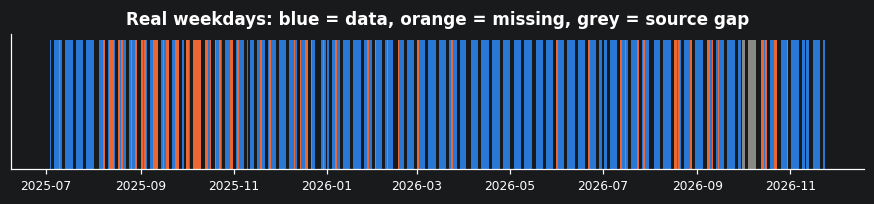

,days
"real weekdays, first record to last date",345
in the source gap (no table covers them),7
coverable real weekdays,338
days with data,268
missing days,70


In [101]:
comp = prep.completeness_by_day(df, calendar)
coverable = comp[~comp["in_source_gap"]]
summary = pd.Series({
    "real weekdays, first record to last date": len(comp),
    "in the source gap (no table covers them)": int(comp["in_source_gap"].sum()),
    "coverable real weekdays": len(coverable),
    "days with data": int(coverable["observed"].sum()),
    "missing days": int((~coverable["observed"]).sum()),
})
print(f"share of coverable weekdays with data: {summary['days with data'] / summary['coverable real weekdays']:.1%}")

# Runs of consecutive missing weekdays (the source gap counts as missing too), longest first.
missing = ~comp["observed"]
run_id = (missing != missing.shift()).cumsum()
runs = (comp[missing].assign(run=run_id[missing]).reset_index(names="date")
        .groupby("run").agg(first=("date", "min"), last=("date", "max"), weekdays=("date", "size"),
                            in_source_gap=("in_source_gap", "sum")))
runs = runs.sort_values(["weekdays", "first"], ascending=[False, True]).reset_index(drop=True)
print(f"{len(runs)} separate gaps; longest runs:")
print(runs.head(5).to_string())

fig, ax = plt.subplots(figsize=(10, 1.6))
ax.bar(comp.index, 1, width=1.0, color=np.where(comp["observed"], BLUE, np.where(comp["in_source_gap"], GREY, ORANGE)))
ax.set_yticks([]); ax.grid(False)
ax.set_title("Real weekdays: blue = data, orange = missing, grey = source gap")
plt.show()
summary.to_frame("days")

rows per observed day: median 324, min 1, max 325
partial days (< 80 % of the median): 35 of 268


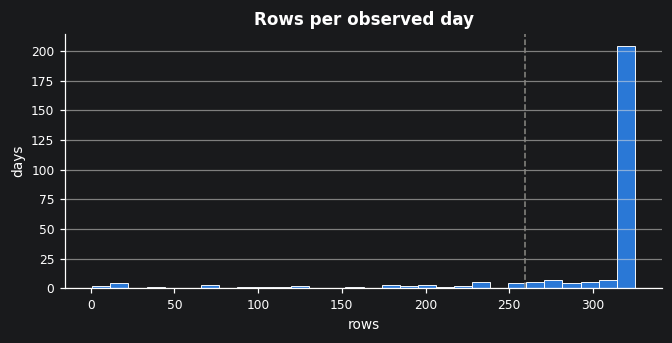

,rows
date,
2025-07-25,1
2025-09-05,4
2026-04-22,18
2026-04-13,21
2026-06-12,21
2026-06-05,21
2025-12-04,34
2025-07-09,68
2025-07-17,74


In [102]:
per_day = comp.loc[comp["observed"], "rows"]
typical = per_day.median()
partial = per_day[per_day < 0.8 * typical]
print(f"rows per observed day: median {typical:.0f}, min {per_day.min()}, max {per_day.max()}")
print(f"partial days (< 80 % of the median): {len(partial)} of {len(per_day)}")
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(per_day, bins=30, color=BLUE, edgecolor="white", linewidth=0.6)
ax.axvline(0.8 * typical, color=GREY, linestyle="--", linewidth=1)
ax.set(title="Rows per observed day", xlabel="rows", ylabel="days")
plt.show()
partial.sort_values().head(10).to_frame("rows")

In [103]:
# Weather and calendar: every date present (asserted in 3.5). Ridership: rows with no schedule period.
no_period = df["schedule_period_name"].isna()
print(f"rows with no ridership period: {no_period.sum():,} ({no_period.mean():.1%}), "
      f"service dates {df.loc[no_period, 'service_date'].min().date()} to {df.loc[no_period, 'service_date'].max().date()}")
print(f"last published period ends {ridership['period_end'].max().date()}")

rows with no ridership period: 10,995 (13.8%), service dates 2026-09-10 to 2026-11-23
last published period ends 2026-09-05


### 6.2 Treat missing days in the main table

*Reason:* the targets of missing days are unknown and must not be imputed, but lag features must know how stale their history is.

In [104]:
grid = prep.build_grid(df, calendar)
grid_summary = pd.Series({
    "grid rows (real weekdays x departures)": len(grid),
    "departures (stop, time of day)": grid[prep.UNIT].drop_duplicates().shape[0],
    "rows on missing days (target NaN)": int(grid["is_missing_day"].sum()),
    "rows missing on observed days": int((grid["is_missing_row"] & ~grid["is_missing_day"]).sum()),
    "observed rows": int((~grid["is_missing_row"]).sum()),
})
assert grid.loc[grid["is_missing_day"], ["late_5min", "early_60s"]].isna().all().all()   # never imputed
grid_summary.to_frame("rows")

,rows
grid rows (real weekdays x departures),112125
"departures (stop, time of day)",325
rows on missing days (target NaN),25025
rows missing on observed days,7524
observed rows,79576


In [105]:
# Lag features were already computed from the last *observed* days (4.4): missing days are skipped,
# not filled. days_since_last_observed tells the model how stale that history is.
stale = df.groupby("days_since_last_observed").agg(
    rows=("late_5min", "size"), late=("late_5min", "mean"), early=("early_60s", "mean"))
stale[["late", "early"]] = stale[["late", "early"]].mul(100).round(2)

# Missing-day rows have no target, so the modelling table keeps observed rows only.
assert len(df) == grid_summary["observed rows"]
stale

,rows,late,early
days_since_last_observed,,,
1.0,65807,4.45,14.04
2.0,9619,8.35,13.58
3.0,2201,4.95,13.72
4.0,978,7.98,16.05
8.0,321,4.98,2.80
10.0,325,0.62,20.92


### 6.3 Treat the ridership gap

*Reason:* service dates after 2026-09-05 have no ridership period. Carry the last period (Summer 2026) forward and flag it, rather than dropping two months of rows.

In [106]:
df = prep.carry_forward_ridership(df, ridership)
assert df[prep.RIDERSHIP_FEATURES].notna().all().all()
df = prep.apply_scaler(df, scaler)      # refresh z_ columns; the scaler was fitted before the gap
print(f"rows with carried-forward ridership: {df['ridership_carried_forward'].sum():,} "
      f"({df['ridership_carried_forward'].mean():.1%})")

rows with carried-forward ridership: 10,995 (13.8%)


### Findings (6)

**Assessment**
- From the first record (2025-07-04) to 2026-11-23 there are 345 real weekdays (Monday–Friday, not a holiday).
  7 of them fall in the source gap 2026-10-01..09 that no table covers, leaving **338 coverable** weekdays.
  **268 have data (79.3 %)**; 70 are missing, spread over 47 separate gaps.
- The longest gaps are the 9 weekdays from 2026-10-01 to 2026-10-14 (7 in the source gap plus 2 days missing for this
  route) and 7 weekdays from 2025-10-06 to 2025-10-15. Most other gaps are 1–3 days.
- Within observed days, a full day has 324–325 departures. **35 of 268 days are partial** (under 80 % of that),
  some almost empty (1, 4 or 18 rows). They are kept as observed days; the route's previous-day rate is noisy after them.
- Weather and calendar are complete. Ridership has no period after 2026-09-05.

**Treatment of missing days (6.2)**
- The full grid of 345 weekdays × 325 departures has 112,125 rows: 79,576 observed, 25,025 on missing days and
  7,524 missing within observed days. Missing rows keep an **empty target**; nothing is imputed.
- History features are computed from the last *observed* days of each departure, so a gap shortens the history
  instead of filling it with guesses. `days_since_last_observed` records how stale it is: 83 % of rows follow a day
  with data (value 1); the rest follow a gap of 2 to 10 weekdays.
- The modelling table contains observed rows only, because missing-day rows have no target.

**Treatment of the ridership gap (6.3)**
- 10,995 rows (13.8 %, service dates 2026-09-10 to 2026-11-23) take the values of the last published period,
  Summer 2026, and are flagged with `ridership_carried_forward = 1`.

## 7. Summary and saved modelling table

**Question.** What table goes into modelling, and what did data understanding and preparation show?

**Why.** The modelling notebook should start from one saved, documented table rather than repeat these steps.

In [107]:
prepared = df[prep.modelling_columns(df)].reset_index(drop=True)

# The same table must come out of prep.prepare(), which the modelling notebook will call.
rebuilt, _ = prep.prepare()
pd.testing.assert_frame_equal(prepared, rebuilt)

prepared.to_parquet(PREPARED_PATH, index=False)    # needs pyarrow
groups = {
    "key": prep.KEY_COLUMNS, "label source": ["deviation"], "targets": prep.TARGETS,
    "calendar / time": ["hour", "minute", "minute_of_day", "day_of_week", "month", "time_period", "schedule_period_name"],
    "stop": ["stop_lon", "stop_lat", "stop_order"],
    "history": [c for c in prepared if c.startswith(("hist_", "route_prev_"))] + ["days_since_last_observed"],
    "weather (d - 1)": [c for c in prepared if c.startswith("wx_prev_")],
    "calendar flags": prep.CALENDAR_FEATURES,
    "ridership": prep.RIDERSHIP_FEATURES + ["ridership_carried_forward"],
    "standardized": [c for c in prepared if c.startswith("z_")],
}
assert sum(len(v) for v in groups.values()) == prepared.shape[1]
print(f"saved {PREPARED_PATH.name}: {prepared.shape[0]:,} rows x {prepared.shape[1]} columns")
pd.Series({k: len(v) for k, v in groups.items()}).to_frame("columns")

saved route91_st_norbert_prepared.parquet: 79,576 rows x 62 columns


,columns
key,4
label source,1
targets,2
calendar / time,7
stop,3
history,8
weather (d - 1),10
calendar flags,4
ridership,3
standardized,20


### Summary

**Modelling table**: `data/mvp/route91_st_norbert_prepared.parquet`, **79,576 rows × 62 columns**, one row per
observed scheduled departure at one stop on a real weekday. `prep.prepare()` rebuilds exactly the same table
(checked with `assert_frame_equal`), so the modelling notebook can call it instead of re-running this notebook.

| Group | Columns |
|---|---|
| key | 4 (`service_date`, `scheduled_time`, `stop_number`, `time_of_day`) |
| label source and targets | `deviation`; `late_5min` 4.95 %, `early_60s` 13.98 % |
| calendar / time | 7 |
| stop | 3 |
| history (no leakage, checked) | 8 |
| weather of the previous day | 10 |
| calendar flags | 4 |
| ridership | 3 |
| standardized copies `z_*` | 20 |

**Data issues and how each was treated**

| Issue | Rows / days | Treatment |
|---|---|---|
| Duplicated (stop, scheduled time) with conflicting deviations | 36 rows | all copies dropped (3.2) |
| \|deviation\| > 3,600 s | 0 rows | rule kept, nothing removed (3.3) |
| `Weekday` rows on a Sunday and on Labour Day | 420 rows, 2 days | dropped (3.4) |
| Whole weekdays without data | 70 of 338 coverable days | not imputed; history from last observed days + `days_since_last_observed` (6.2) |
| Source gap between archive and recent table | 7 weekdays | counted as missing (6.1) |
| Ridership not published after 2026-09-05 | 10,995 rows | last period carried forward, flagged (6.3) |

**Assumptions** (all in `mvp_config.py`)
- Ridership time periods: Morning before 09:00, Mid-Day 09:00–15:00, PM Peak 15:00–18:00.
- Weather features use day *d* − 1, because same-day observations are not known the day before.
- Stop order is approximated by latitude; the data has no stop sequence.
- `TRAIN_END = 2026-06-30` is provisional and only used to fit the scaler.

**Open questions for modelling**
- Fix the rolling time split (and `TRAIN_END` with it) before training.
- How to fill empty history values for the linear model (about 2 % of rows, all in July 2025).
- Whether nearly empty partial days should count as observed for the route-level previous-day rate.
- `residential_ban` covers 6 days only and may be dropped.
- Same-day weather (`prep.join_weather(..., lag_days=0)`) may be run once as an upper bound, reported separately.